In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image


In [2]:
sns.set_theme()

# Custom anomaly vs. normal box experiment

In [3]:
results_df = pd.read_csv("experiments/l2_distance_anomaly_vs_normal_box_validation_multiple_seeds.csv")

In [4]:
results_df = results_df[["image_name", "l2_distance_anomaly_box", "l2_distance_normal_box", "box_size"]]


In [5]:
results_df

,image_name,l2_distance_anomaly_box,l2_distance_normal_box,box_size
0,00124_60,91.973701,47.969856,"(96, 96)"
1,00124_70,90.002373,48.246311,"(96, 96)"
2,00124_80,83.946426,50.524097,"(96, 96)"
3,00124_90,54.061226,38.433231,"(96, 96)"
4,00134_60,51.200714,22.146847,"(96, 96)"
...,...,...,...,...
655,01597_90,77.239258,30.875351,"(96, 80)"
656,01646_60,50.662373,10.140795,"(96, 80)"
657,01646_70,29.354994,13.656301,"(96, 80)"
658,01646_80,23.254526,27.066849,"(96, 80)"



Image: 


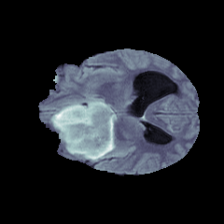


Segmentation: 


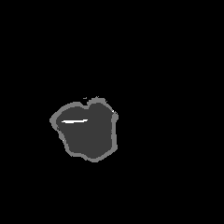


Anomaly box: 


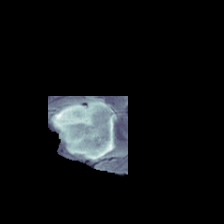


Normal box: 


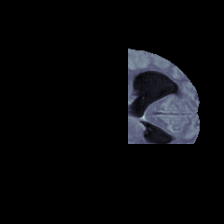


Context: 


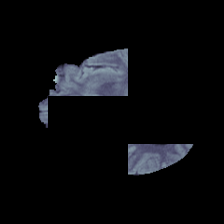

In [52]:
# Example of selected boxes

image_name = "00134_60"

print("\nImage: ")
display(Image.open(f"experiments/custom_anomaly_normal_boxes/{image_name}_image.png"))
print("\nSegmentation: ")
display(Image.open(f"experiments/custom_anomaly_normal_boxes/{image_name}_segmentation.png"))
print("\nAnomaly box: ")
display(Image.open(f"experiments/custom_anomaly_normal_boxes/{image_name}_anomaly_pixels_mask_image.png"))
print("\nNormal box: ")
display(Image.open(f"experiments/custom_anomaly_normal_boxes/{image_name}_normal_pixels_mask_image.png"))
print("\nContext: ")
display(Image.open(f"experiments/custom_anomaly_normal_boxes/{image_name}_context_image.png"))


In [32]:
results_df["l2_distance_anomaly_box"].mean()

53.14833298740965

In [33]:
results_df["l2_distance_normal_box"].mean()

34.05695187106277

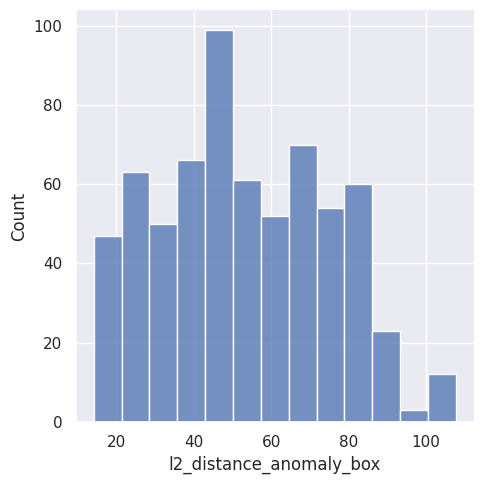

In [6]:
sns.displot(data=results_df, x="l2_distance_anomaly_box", kind="hist")

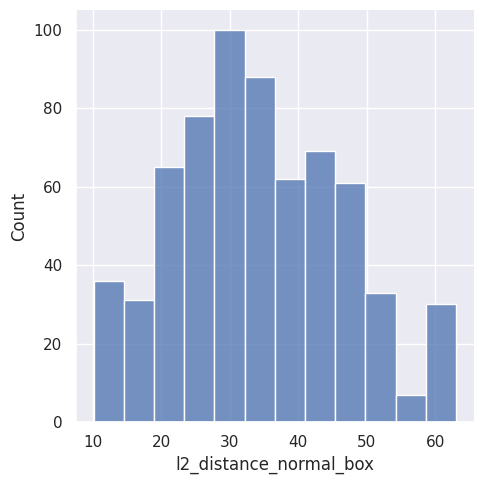

In [7]:
sns.displot(data=results_df, x="l2_distance_normal_box", kind="hist")

In [8]:
l2_distances = results_df["l2_distance_anomaly_box"].to_list() + results_df["l2_distance_normal_box"].to_list()
box_types = ["anomaly"] * len(results_df["l2_distance_anomaly_box"].to_list()) + ["normal"] * len(results_df["l2_distance_normal_box"].to_list())

differences_plot_df = pd.DataFrame({"l2_distance": l2_distances, "box_type": box_types})


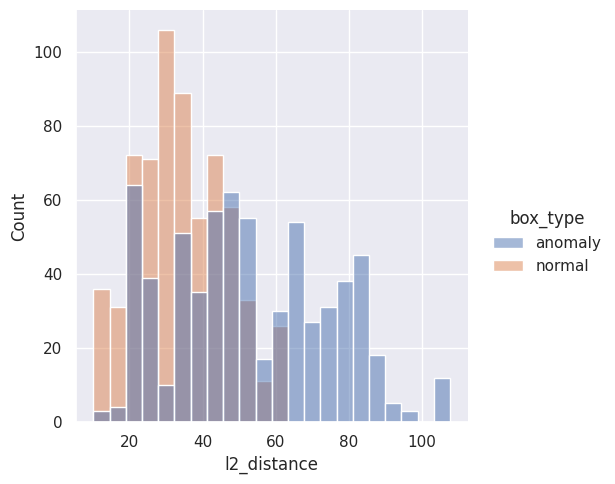

In [9]:
sns.displot(differences_plot_df, x="l2_distance", hue="box_type", kind="hist")

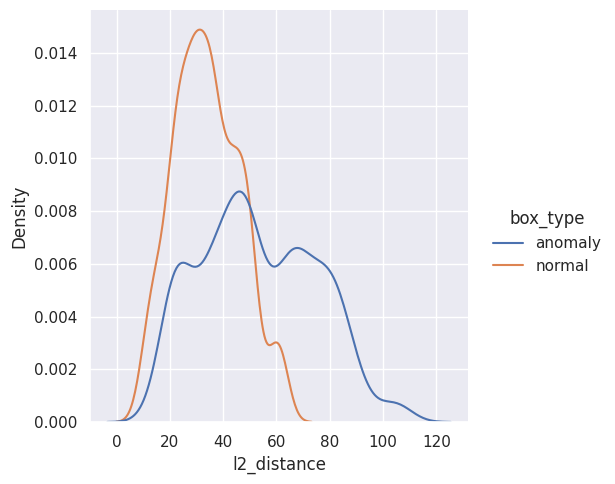

In [10]:
sns.displot(differences_plot_df, x="l2_distance", hue="box_type", kind="kde")

# Random boxes experiment

In [11]:
results_random_box_df = pd.read_csv("experiments/l2_distance_random_box_multiple_seeds.csv")


In [12]:
results_random_box_df

,image_name,label,l2_distance,box_size,seed
0,00124_60,1,70.383705,"(96, 96)",0
1,00124_70,1,56.705956,"(96, 96)",0
2,00124_80,1,42.480804,"(96, 96)",0
3,00124_90,1,27.245188,"(96, 96)",0
4,00134_60,1,40.655178,"(96, 96)",0
...,...,...,...,...,...
2485,01505_60,0,18.025101,"(80, 96)",29
2486,01514_99,0,15.189940,"(80, 96)",29
2487,01555_60,0,26.343973,"(80, 96)",29
2488,01616_99,0,26.079399,"(80, 96)",29


In [72]:
results_random_box_df[(results_random_box_df["image_name"] == "00134_60") & (results_random_box_df["seed"].isin([10, 11, 12, 13]))]

,image_name,label,l2_distance,box_size,seed
834,00134_60,1,27.795519,"(96, 80)",10
917,00134_60,1,37.335239,"(80, 96)",11
1000,00134_60,1,44.836010,"(96, 80)",12
1083,00134_60,1,41.893986,"(80, 96)",13



Image: 


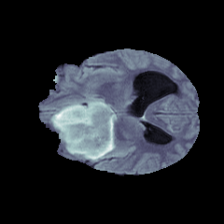


Random box: 


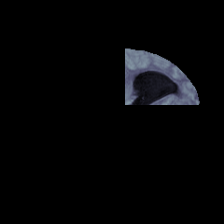


Context: 


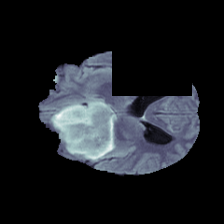

In [73]:
# Example of sampled boxes

image_name = "00134_60"
box_id = 10

print("\nImage: ")
display(Image.open(f"experiments/random_boxes/{image_name}_image.png"))
print("\nRandom box: ")
display(Image.open(f"experiments/random_boxes/{image_name}_random_pixels_mask_image_{box_id}.png"))
print("\nContext: ")
display(Image.open(f"experiments/random_boxes/{image_name}_context_image_{box_id}.png"))


## Using 30 randomly sampled boxes

Anomaly images: mean L2 distance:  38.044355036273146
Normal images: mean L2 distance:  25.687600402342966


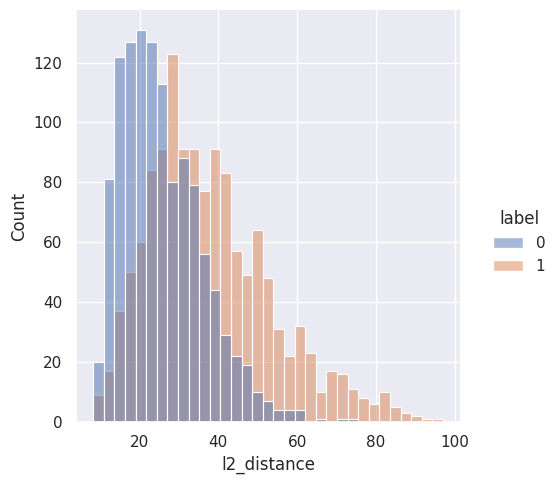

In [13]:
print("Anomaly images: mean L2 distance: ", results_random_box_df[results_random_box_df["label"] == 1]["l2_distance"].mean())
print("Normal images: mean L2 distance: ", results_random_box_df[results_random_box_df["label"] == 0]["l2_distance"].mean())

sns.set_theme()
sns.displot(results_random_box_df, x="l2_distance", hue="label", kind="hist")

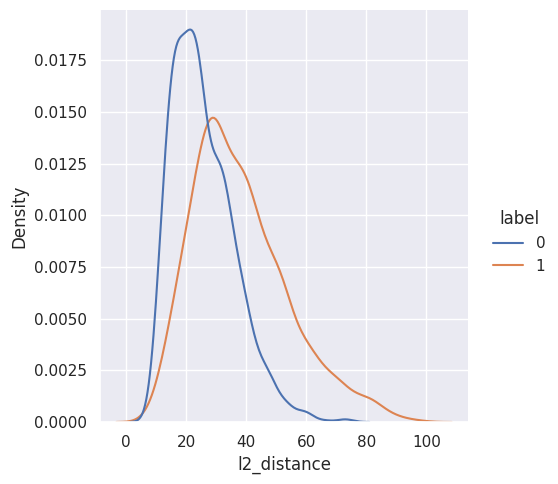

In [22]:
sns.displot(results_random_box_df, x="l2_distance", hue="label", kind="kde")

In [17]:
normal_image_mean_l2_distances_per_num_random_boxes = {}
anomaly_image_mean_l2_distances_per_num_random_boxes = {}

box_numbers = sorted(set(results_random_box_df["seed"].to_list()))

for box_num in box_numbers:
    normal_df = results_random_box_df[
        (results_random_box_df["label"] == 0) & 
        (results_random_box_df["seed"] <= box_num)]
    normal_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = normal_df["l2_distance"].mean()
    
    anomaly_df = results_random_box_df[
        (results_random_box_df["label"] == 1) & 
        (results_random_box_df["seed"] <= box_num)]
    anomaly_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = anomaly_df["l2_distance"].mean()


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Normal images')]

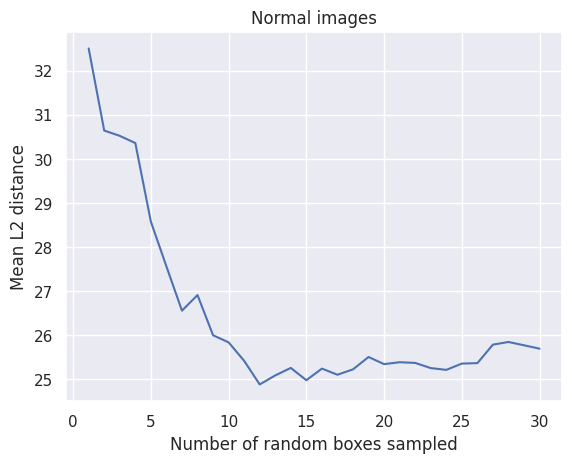

In [30]:
ax = sns.lineplot(x=list(normal_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(normal_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Normal images")


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Anomaly images')]

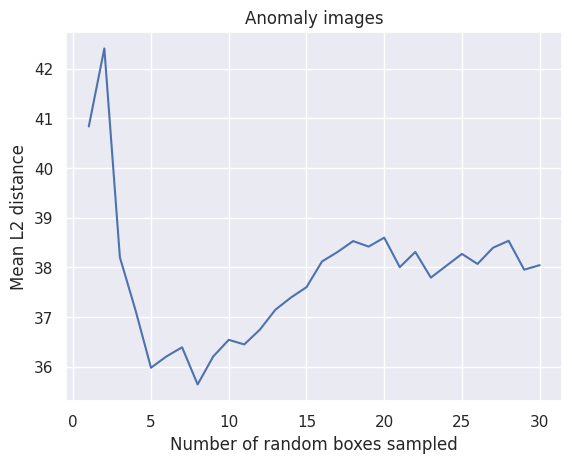

In [31]:
ax = sns.lineplot(x=list(anomaly_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(anomaly_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Anomaly images")